# 03 — Statistical models (Nixtla `statsforecast`)

One model per series, fitted at each origin. The candidates:

| Family | Models | What they assume |
|---|---|---|
| Baselines | Naive, SeasonalNaive(12), Mean3/6/12 (window averages), HistoricAverage | nothing, or a flat level |
| Exponential smoothing | SES (optimised α), AutoETS (error/trend/season chosen by AICc, season 12) | a level (trend, season) updated each month |
| Theta | AutoTheta (season 12) | a damped trend plus SES, the M3 winner |
| ARIMA | AutoARIMA (season 12) | autocorrelation structure |
| Intermittent | ADIDA, Croston (optimised), TSB | demand sizes and intervals apart |

The protocol is notebook 02's: 60 households, 48 months, 7 origins every 2 months, 12 months
ahead. A second, **short** panel (the same households' last 30 months, 7 origins every month,
trained on 12 to 18 months) tests the app's rule that only averages compete below 24 months.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import (
    ADIDA, TSB, AutoARIMA, AutoETS, AutoTheta, CrostonOptimized, HistoricAverage, Naive,
    SeasonalNaive, SimpleExponentialSmoothingOptimized, WindowAverage,
)

import study

warnings.filterwarnings("ignore", category=RuntimeWarning)  # ETS on flat trainings
v = study.bench()

def candidates(seasonal: bool = True) -> list:
    out = [
        Naive(), WindowAverage(3, alias="Mean3"), WindowAverage(6, alias="Mean6"),
        HistoricAverage(), SimpleExponentialSmoothingOptimized(alias="SES"),
        AutoETS(season_length=12 if seasonal else 1, alias="ETS"),
        AutoTheta(season_length=12 if seasonal else 1, alias="Theta"),
        AutoARIMA(season_length=12 if seasonal else 1, alias="ARIMA"),
        ADIDA(), CrostonOptimized(alias="Croston"), TSB(alpha_d=0.1, alpha_p=0.1),
    ]
    if seasonal:
        out += [SeasonalNaive(12), WindowAverage(12, alias="Mean12")]
    return out

def run(frame: pd.DataFrame, models: list, **kw) -> pd.DataFrame:
    # Croston-family models fail on a training without any non-empty month: they then fall back
    # on the historic average (rare; counted below).
    return StatsForecast(models=models, freq="MS", n_jobs=-1, fallback_model=HistoricAverage()).cross_validation(
        df=frame[["unique_id", "ds", "y"]], h=12, **kw
    )

cv = study.cached("stats_bench", lambda: run(v, candidates(), n_windows=7, step_size=2))
MODELS = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
scores = study.cached("stats_bench_scores", lambda: study.point_scores(cv, v, MODELS))
table = study.summary(scores, baseline="Mean6")
table.round(3)

,MASE,MASE median,RMSSE,WAPE,bias,beats baseline
model,,,,,,
ARIMA,0.838,0.747,0.814,0.118,0.006,0.581
ETS,0.850,0.735,0.807,0.112,0.007,0.582
Theta,0.911,0.796,0.841,0.122,-0.006,0.530
TSB,0.912,0.804,0.868,0.163,0.017,0.548
ADIDA,0.912,0.807,0.869,0.164,0.013,0.531
Mean12,0.917,0.823,0.870,0.165,0.012,0.546
HistoricAverage,0.927,0.811,0.878,0.164,0.023,0.517
SES,0.928,0.783,0.890,0.158,0.023,0.514
Croston,0.933,0.813,0.875,0.169,0.007,0.518


## Which ones are really different?

Average ranks of the MASE over the 4,606 series-origins, the Friedman test and the Nemenyi
critical difference (two models closer than it cannot be told apart at 5 %):

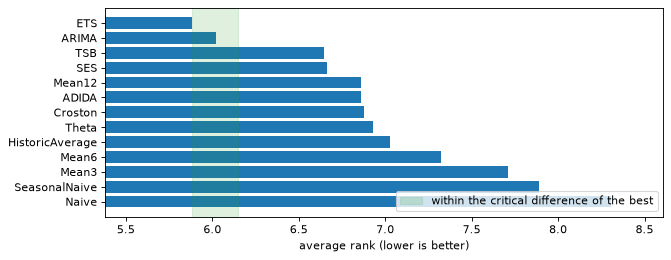

Friedman p = 0; Nemenyi CD = 0.269
tied with the best: ['ETS', 'ARIMA']


In [2]:
ranks, p, cd = study.friedman_nemenyi(scores)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(ranks.index[::-1], ranks.values[::-1], color="tab:blue")
best = ranks.iloc[0]
ax.axvspan(best, best + cd, color="tab:green", alpha=0.15, label="within the critical difference of the best")
ax.set(xlabel="average rank (lower is better)", xlim=(ranks.min() - 0.5, ranks.max() + 0.3))
ax.legend(loc="lower right")
plt.show()
print(f"Friedman p = {p:.2g}; Nemenyi CD = {cd:.3f}")
print("tied with the best:", list(ranks[ranks <= best + cd].index))

## By category: no single winner

The mean MASE of each model by category (rows), then the best of each row:

In [3]:
scores["category"] = scores["unique_id"].str.split("/").str[1]
by_cat = scores.dropna(subset=["mase"]).pivot_table(index="category", columns="model", values="mase", aggfunc="mean")
show = by_cat[["Mean6", "HistoricAverage", "SeasonalNaive", "SES", "ETS", "Theta", "ARIMA", "ADIDA", "Croston", "TSB"]]
print(show.round(2).to_string())
print()
print("best per category:", show.idxmin(axis=1).to_dict())

model          Mean6  HistoricAverage  SeasonalNaive   SES   ETS  Theta  ARIMA  ADIDA  Croston   TSB
category                                                                                            
Children        0.78             0.77           0.58  0.78  0.62   0.64   0.65   0.77     0.77  0.76
Gifts           1.23             1.16           1.16  1.30  1.30   1.43   1.17   1.15     1.20  1.15
Groceries       0.85             0.84           0.84  0.85  0.84   0.85   0.84   0.84     0.84  0.83
Health          0.98             0.93           1.20  0.98  0.96   1.03   0.98   0.95     0.96  0.94
Home            0.92             0.85           1.12  0.90  0.89   0.97   0.88   0.87     0.88  0.86
Housing         0.89             0.92           0.06  0.74  0.06   0.12   0.12   0.93     1.12  0.91
Leisure         1.02             0.92           0.74  1.07  0.92   0.94   0.80   0.97     0.97  0.93
Miscellaneous   0.82             0.76           1.03  0.81  0.80   0.84   0.80   0.79     0

## By horizon

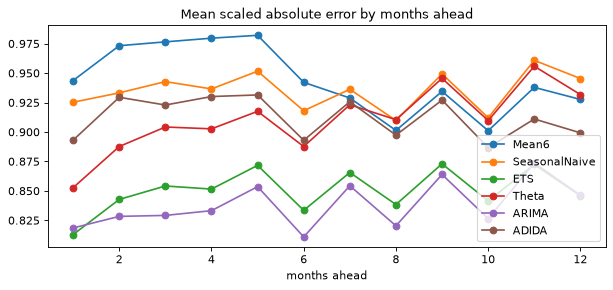

In [4]:
hz = study.by_horizon(cv, v, ["Mean6", "SeasonalNaive", "ETS", "Theta", "ARIMA", "ADIDA"])
hz.plot(marker="o", title="Mean scaled absolute error by months ahead")
plt.xlabel("months ahead")
plt.show()

## Diebold–Mariano on two candidates, series by series

For each series, ETS against the 6-month mean on the 84 forecast months (7 origins × 12),
Diebold–Mariano with h = 12 (the overlapping horizons make errors autocorrelated). The share of
series where either one is significantly better at 5 % (the selection uses the mean absolute error
per series, which ranks models like the MASE since the scale is the series' own):

In [5]:
res = []
for uid, g in cv.groupby("unique_id"):
    e1, e2 = (g["y"] - g["ETS"]).to_numpy(), (g["y"] - g["Mean6"]).to_numpy()
    if np.allclose(e1, e2):
        continue
    dm, pv = study.diebold_mariano(e1, e2, h=12)
    res.append((uid, dm, pv))
dmf = pd.DataFrame(res, columns=["unique_id", "dm", "p"])
print(f"ETS significantly better: {((dmf.p < 0.05) & (dmf.dm < 0)).mean():.1%}; "
      f"6-month mean significantly better: {((dmf.p < 0.05) & (dmf.dm > 0)).mean():.1%}; "
      f"no significant difference: {(dmf.p >= 0.05).mean():.1%} of {len(dmf)} series")

ETS significantly better: 17.2%; 6-month mean significantly better: 7.0%; no significant difference: 75.8% of 658 series


## Short histories: the 24-month rule

The app lets only the averages compete with the baseline while a series has fewer than 24
months (F-FCT-3), on the reviewer's argument that with 5 to 11 overlapping cuts a richer model
wins by chance. Here the same households' last 30 months, cut every month from month 12 to 18:

In [6]:
short = v[v["ds"] > v["ds"].max() - pd.DateOffset(months=30)]
cv_s = study.cached("stats_short", lambda: run(short, candidates(seasonal=True), n_windows=7, step_size=1))
scores_s = study.point_scores(cv_s, short, MODELS)
study.summary(scores_s, baseline="Mean6").round(3)

,MASE,MASE median,RMSSE,WAPE,bias,beats baseline
model,,,,,,
ARIMA,0.913,0.788,0.960,0.156,0.017,0.540
Mean12,0.941,0.817,0.951,0.165,0.009,0.553
HistoricAverage,0.942,0.817,0.952,0.166,0.010,0.549
ADIDA,0.951,0.816,0.960,0.167,0.009,0.524
SeasonalNaive,0.955,0.858,1.008,0.125,0.009,0.444
TSB,0.958,0.811,0.968,0.172,0.007,0.530
Mean6,0.965,0.838,0.973,0.174,0.002,0.000
ETS,0.977,0.813,0.977,0.167,0.008,0.524
SES,0.980,0.783,0.998,0.164,0.016,0.500


## Does choosing per series pay, and with which margin?

The app picks, per series, the candidate with the lowest back-test MASE, and keeps the baseline
unless the winner is at least **10 %** better (F-FCT-4). We test that rule **out of sample**: at
each of the last two origins, a series' choice is made only from the errors of earlier origins
whose forecast months were already entered at that origin (as the app would), then judged on
the 12 months that follow. Margins 0 to 30 %, against always the 6-month mean and against the
single model best on average.

In [7]:
def select_and_score(cv: pd.DataFrame, scores_by_model: pd.DataFrame, models: list[str], margin: float,
                     restrict: list[str] | None = None) -> float:
    cv = study.with_steps(cv)
    cuts = sorted(cv["cutoff"].unique())
    out = []
    pool = restrict or models
    sc = scores_by_model.set_index(["unique_id", "cutoff", "model"])["scale"]
    for c in cuts[-2:]:
        past = cv[cv["ds"] <= c]
        if past.empty:
            continue
        mae = {m: (past["y"] - past[m]).abs().groupby(past["unique_id"]).mean() for m in pool}
        mae = pd.DataFrame(mae)
        best = mae.idxmin(axis=1)
        keep = mae.min(axis=1) <= (1 - margin) * mae["Mean6"]
        choice = best.where(keep, "Mean6")
        test = cv[cv["cutoff"] == c]
        for uid, g in test.groupby("unique_id"):
            m = choice.get(uid, "Mean6")
            s = sc.get((uid, c, "Mean6"), np.nan)
            if s and s > 0:
                out.append((g["y"] - g[m]).abs().mean() / s)
    return float(np.nanmean(out))

def margins_table(cv, scores, models, restrict=None):
    rows = {f"margin {int(m * 100)} %": select_and_score(cv, scores, models, m, restrict) for m in (0, 0.05, 0.1, 0.2, 0.3)}
    rows["always Mean6"] = select_and_score(cv, scores, models, 10.0)
    return pd.Series(rows, name="out-of-sample MASE")

mt_long = margins_table(cv, scores, MODELS)
mt_short = margins_table(cv_s, scores_s, MODELS)
mt_short_avg = margins_table(cv_s, scores_s, MODELS, restrict=["Mean6", "Mean3", "HistoricAverage"])
pd.DataFrame({"48 months, all candidates": mt_long, "30 months, all candidates": mt_short,
              "30 months, averages only": mt_short_avg}).round(3)

,"48 months, all candidates","30 months, all candidates","30 months, averages only"
margin 0 %,0.846,0.927,0.932
margin 5 %,0.850,0.898,0.940
margin 10 %,0.854,0.894,0.946
margin 20 %,0.859,0.895,0.955
margin 30 %,0.860,0.895,0.958
always Mean6,0.946,0.956,0.956


## What the statistical models say

**On 48 months of history** (training 24 to 36 months at the origins):

- **AutoARIMA (MASE 0.838) and AutoETS (0.850)** lead, and are the only two the Nemenyi test
  cannot separate from the best; they cut the error of the 6-month mean (0.944) by about 10 %
  on average and beat it on 58 % of the series-origins, with the lowest WAPE (11–12 % of the
  money) of all. Theta, the intermittent methods (TSB, ADIDA) and the long averages (Mean12,
  historic) form a second group around 0.91–0.93; the naive method is last (1.17).
- **No model wins everywhere**: the seasonal naive is best for children and leisure (school
  and summer patterns), ETS for salaries and for the housing's yearly property tax, the
  historic average for the noisy categories (health, home, shopping, miscellaneous), TSB for
  gifts and transport. A per-series choice is the right design.
- Series by series, Diebold–Mariano finds ETS significantly better than the 6-month mean on
  17 % of the series, worse on 7 %, and **no significant difference on 76 %**: with 84 forecast
  months per series, most differences are within noise. Hence a margin before leaving the
  baseline.

**On 30 months** (training 12 to 18 months), the ranking moves: ARIMA still leads (0.913) but
ETS falls to 0.977 and Theta to 1.157, while the long averages (Mean12, historic, 0.94) hold.

**Choosing per series, out of sample** (the choice made only from errors already observable at
the origin, judged on the next 12 months):

| | 48 months, all candidates | 30 months, all candidates | 30 months, averages only |
|---|---|---|---|
| margin 0 % | **0.846** | 0.927 | **0.932** |
| margin 10 % (the app) | 0.854 | **0.894** | 0.946 |
| always the 6-month mean | 0.946 | 0.956 | 0.956 |

- Per-series selection beats always using the baseline by **10 %** with two years or more of
  history, and by **6 %** with 12–18 months.
- The **10 % margin** costs almost nothing with long histories (0.854 against 0.846) and
  **protects** short ones, where choosing the raw winner (margin 0) overfits the few origins
  (0.927 against 0.894). It is a sound default.
- **Restricting short series to the averages (the 24-month rule) is worse** than letting every
  candidate compete behind the 10 % margin (0.946 against 0.894): on this panel the margin
  already does the protecting, and ARIMA and the seasonal naive carry real information from
  12 months on. The evidence argues for relaxing the rule (notebook 09).